## **Messwerte**

In [81]:
import numpy as np
import pandas as pd
import uncertainties as uc
import uncertainties.unumpy as unp


df = pd.read_csv('F0000CH1.CSV', usecols=[3, 4], header=None, names=['Time', 'Voltage'])

t_data = df["Time"].to_numpy()[280:] #Zeit in sekunden
U_data = df["Voltage"].to_numpy()[280:]

t_Fehler = 0
U_Fehler = 0.4

t = unp.uarray(t_data, t_Fehler)
U = unp.uarray(U_data, U_Fehler)


## **Plot mit Regression**

lambda aus Exponentiellem Fit: lambda = (1.02+/-0.07)e+03



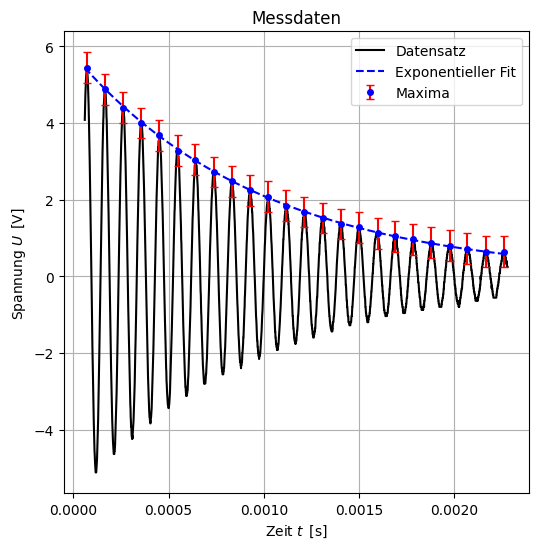

In [82]:
import scipy
import matplotlib.pyplot as plt

def f(x, lmbda, A): #Fit Funktion
    return A*np.exp(-lmbda*x)

peaks = scipy.signal.find_peaks(unp.nominal_values(U), distance= 15, height=0.1)[0] #get the indices of the peaks
U_peaks = unp.uarray(unp.nominal_values(U)[peaks], unp.std_devs(U)[peaks])

coefficients, pcov = scipy.optimize.curve_fit(f, unp.nominal_values(t)[peaks], unp.nominal_values(U)[peaks], sigma= unp.std_devs(U)[peaks], absolute_sigma= True)

lmbda = uc.ufloat(coefficients[0], np.sqrt(pcov[0,0]))

A = uc.ufloat(coefficients[1], np.sqrt(pcov[1,1]))

print(f"lambda aus Exponentiellem Fit: lambda = {lmbda}\n")


"""--------------------------------------------------------------------------------------------------------------------------------------------------------------------"""
#Plot

fig, ax0 = plt.subplots(1,1, figsize = (6,6))

ax0.plot(unp.nominal_values(t), unp.nominal_values(U), label = "Datensatz", color = "black")
ax0.errorbar(unp.nominal_values(t)[peaks], unp.nominal_values(U_peaks) , yerr= unp.std_devs(U)[peaks] , fmt="o", label="Maxima", color="blue", markersize=4, capsize=3, ecolor="r")
ax0.plot(unp.nominal_values(t), f(unp.nominal_values(t), lmbda.nominal_value, A.nominal_value), color = "blue", linestyle = "--", label = "Exponentieller Fit")


ax0.set_xlabel("Zeit $t\\,$ [s]")
ax0.set_ylabel("Spannung $U \\,$ [V]")
ax0.grid(True)
ax0.set_title("Messdaten")
ax0.legend()


## **Logarithmischer Plot und Dekrement**

lambda aus Fit: lambda = (-1.02+/-0.07)e+03

lambda aus den Log-Dekrementen: lambda = (9.8+/-2.9)e+02



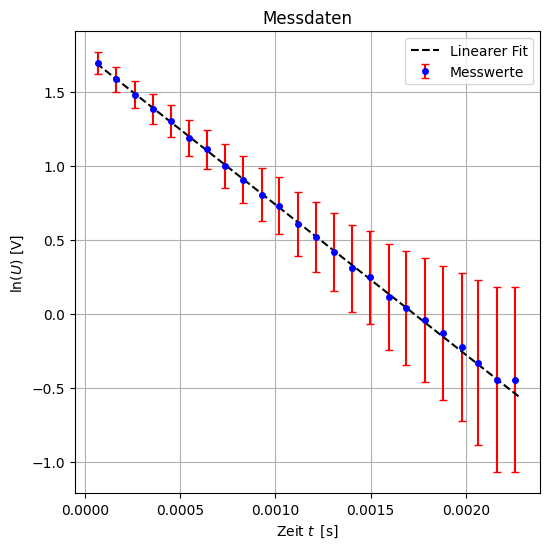

In [83]:

U_log = unp.log(U_peaks)

def f(x, k, c):
    return k*x +c

coefficients, pcov = scipy.optimize.curve_fit(f, unp.nominal_values(t)[peaks], unp.nominal_values(U_log), sigma= unp.std_devs(U_log), absolute_sigma= True)
k = uc.ufloat(coefficients[0], np.sqrt(pcov[0,0]))
c = coefficients[1]

print(f"lambda aus Fit: lambda = {k}\n")

#Plot
fig, ax0 = plt.subplots(1,1, figsize = (6,6))

ax0.errorbar(unp.nominal_values(t)[peaks], unp.nominal_values(U_log) , yerr= unp.std_devs(U_log), fmt="o", label="Messwerte", color="blue", markersize=4, capsize=3, ecolor="r")
ax0.plot(unp.nominal_values(t), f(unp.nominal_values(t), k.nominal_value, c), color = "black", linestyle = "--", label = "Linearer Fit")

ax0.set_xlabel("Zeit $t\\,$ [s]")
ax0.set_ylabel("ln($U$) [V]")
ax0.grid(True)
ax0.set_title("Messdaten")
ax0.legend()


#Logarithmische Dekremente

logDeks = unp.log(U_peaks[:-1] / U_peaks[1:])

t_peaks = unp.uarray(unp.nominal_values(t)[peaks], unp.std_devs(t)[peaks])
deltaT = t_peaks[1:] - t_peaks[:-1]

lmda_logs = (logDeks/deltaT).mean()

print(f"lambda aus den Log-Dekrementen: lambda = {lmda_logs}\n")